# Experimento: estimar el precio de pisos en València

Aplica el método de `experimento_pipeline.ipynb` a datos reales de la ciudad de València.

**Qué predice:** el precio **anunciado** de un piso en venta en 2018. No es un precio de compraventa ni un precio actual.

**Datos:** [`idealista18`](https://github.com/paezha/idealista18), de Rey-Blanco, Arbués, López y Páez, publicado en *Environment and Planning B* (2024). Contiene información disponible bajo la licencia [Open Database License (ODbL) v1.0](https://opendatacommons.org/licenses/odbl/1-0/). Los autores añadieron un ruido aleatorio ligero a precios y coordenadas para proteger la privacidad.

**Reglas del experimento:**

- Partición temporal: se entrena con los tres primeros trimestres de 2018 y se evalúa con el cuarto.
- Los modelos se eligen con validación temporal dentro de los tres primeros trimestres. El test se usa una sola vez.
- El modelo debe superar una referencia sencilla: el precio por m² de la zona multiplicado por la superficie.

In [1]:
import hashlib
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdata
import sklearn
from sklearn import metrics
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}' if abs(v) < 10 else f'{v:,.0f}')
SEED = 42
COLOR = '#2a78b4'
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__, '| rdata', rdata.__version__)

scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.2.6 | rdata 0.11.2


## 1. Descargar los datos

La descarga apunta a un commit fijo y comprueba el hash del archivo, de modo que el experimento siempre usa exactamente los mismos datos. El archivo se guarda en `data_valencia/`, que git ignora; la carpeta `data/` sigue reservada a la entrega original.

In [2]:
COMMIT = 'e9ef80618f8a9cc28f672ac138f298bbd519918e'
URL = f'https://raw.githubusercontent.com/paezha/idealista18/{COMMIT}/data/Valencia_Sale.rda'
SHA256 = '0d8037037feb6e12e7103f5b2296b86e325248beb83877262c667abef296c6be'
RUTA = Path('data_valencia/Valencia_Sale.rda')

if not RUTA.exists():
    RUTA.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, RUTA)

obtenido = hashlib.sha256(RUTA.read_bytes()).hexdigest()
assert obtenido == SHA256, f'El archivo descargado no coincide con el esperado: {obtenido}'

clases = dict(rdata.conversion.DEFAULT_CLASS_MAP)
for clase in ['sf', 'sfc', 'sfc_POINT', 'XY', 'POINT', 'bbox', 'crs']:
    clases.setdefault(clase, lambda objeto, atributos: objeto)
contenido = rdata.conversion.convert(rdata.parser.parse_file(RUTA), clases)['Valencia_Sale']

raw = pd.DataFrame({str(k): np.asarray(v) for k, v in contenido.items() if str(k) != 'geometry'})
raw['ASSETID'] = raw['ASSETID'].astype(str)
numericas = raw.columns.drop('ASSETID')
raw[numericas] = raw[numericas].apply(pd.to_numeric, errors='coerce')
print(raw.shape)

(33622, 41)


## 2. Tres trampas de los datos

**Una columna contiene la respuesta.** `UNITPRICE` multiplicado por la superficie da exactamente `PRICE`. Si se usa como variable, el resultado parece espectacular y no sirve de nada: para conocerla ya hay que saber el precio.

**Los valores ausentes parecen números.** R representa el entero ausente como `-2147483648`, y el lector de Python lo deja tal cual. Sin tratarlo, el año medio de construcción sería negativo.

**Un mismo piso aparece varias veces.** Hay filas con el mismo `ASSETID` y trimestre, con precio y coordenadas distintos. La diferencia de precio mediana es de un 4,75 %, aunque en un 1 % de los casos supera el 60 %. Se conserva una fila por piso, la de precio mediano.

In [3]:
ratio = raw['UNITPRICE'] * raw['CONSTRUCTEDAREA'] / raw['PRICE']
print(f'UNITPRICE x superficie / PRICE: de {ratio.min():.4f} a {ratio.max():.4f}')

NA_R = -2147483648
print('Valores ausentes ocultos:', {c: f'{(raw[c] == NA_R).mean():.1%}' for c in numericas if (raw[c] == NA_R).any()})
limpio = raw.replace(NA_R, np.nan)

limpio = limpio.sort_values(['ASSETID', 'PRICE']).reset_index(drop=True)
posicion = limpio.groupby('ASSETID').cumcount()
mitad = (limpio.groupby('ASSETID')['PRICE'].transform('size') - 1) // 2
data = limpio[posicion == mitad].sort_values(['PERIOD', 'ASSETID']).reset_index(drop=True)

assert data['ASSETID'].is_unique
print(f'Filas: {len(raw)} originales, {len(data)} tras dejar una por piso')
print('Por trimestre:', data['PERIOD'].value_counts().sort_index().to_dict())

UNITPRICE x superficie / PRICE: de 1.0000 a 1.0000
Valores ausentes ocultos: {'CONSTRUCTIONYEAR': '39.3%', 'FLOORCLEAN': '5.1%', 'FLATLOCATIONID': '16.1%'}
Filas: 33622 originales, 27391 tras dejar una por piso
Por trimestre: {201803: 7502, 201806: 4652, 201809: 5037, 201812: 10200}


## 3. Variables y partición

Se excluye todo lo que no se conocería antes de fijar el precio o que no aporta como variable: `PRICE`, `UNITPRICE`, `PARKINGSPACEPRICE`, `ASSETID` y `PERIOD`.

**Pisos que reaparecen con otro identificador.** El mismo piso puede volver a publicarse en otro trimestre con un `ASSETID` distinto, y entonces el modelo solo tendría que recordar su precio. Se marcan como posibles re-publicaciones los pisos del test cuyas características coinciden exactamente con un piso de entrenamiento. La métrica principal los excluye. Puede haber falsos positivos, como pisos iguales de un mismo edificio, lo que hace la evaluación más exigente.

In [4]:
EXCLUIDAS = ['PRICE', 'UNITPRICE', 'PARKINGSPACEPRICE', 'ASSETID', 'PERIOD']
VARIABLES = [c for c in data.columns if c not in EXCLUIDAS]
HUELLA = ['CONSTRUCTEDAREA', 'ROOMNUMBER', 'BATHNUMBER', 'FLOORCLEAN', 'CADCONSTRUCTIONYEAR', 'CADDWELLINGCOUNT',
          'CADMAXBUILDINGFLOOR', 'CADASTRALQUALITYID', 'HASLIFT', 'HASTERRACE']

desarrollo = data[data['PERIOD'] < 201812].reset_index(drop=True)
test = data[data['PERIOD'] == 201812].reset_index(drop=True)
assert not set(desarrollo['ASSETID']) & set(test['ASSETID'])

huellas_train = set(map(tuple, desarrollo[HUELLA].fillna(-1).to_numpy()))
reaparece = np.array([h in huellas_train for h in map(tuple, test[HUELLA].fillna(-1).to_numpy())])

X_dev, y_dev = desarrollo[VARIABLES], desarrollo['PRICE']
X_test, y_test = test[VARIABLES], test['PRICE']

# Validación temporal: Q1 -> Q2 y Q1 + Q2 -> Q3.
periodo = desarrollo['PERIOD'].to_numpy()
cv = [(np.where(periodo == 201803)[0], np.where(periodo == 201806)[0]),
      (np.where(periodo <= 201806)[0], np.where(periodo == 201809)[0])]

print(f'Desarrollo: {len(desarrollo)} | Test: {len(test)}, de ellos {reaparece.sum()} ({reaparece.mean():.1%}) posibles re-publicaciones')
print(f'{len(VARIABLES)} variables')
print('Mediana de €/m² por trimestre:', data.groupby('PERIOD')['UNITPRICE'].median().round(0).to_dict())

Desarrollo: 17191 | Test: 10200, de ellos 1202 (11.8%) posibles re-publicaciones
36 variables


Mediana de €/m² por trimestre: {201803: 1442.0, 201806: 1442.0, 201809: 1508.0, 201812: 1600.0}


## 4. Modelos candidatos

- **€/m² de toda la ciudad:** la mediana del precio por m² multiplicada por la superficie.
- **€/m² por zona:** igual, pero por celdas de unos 500 metros. Es la referencia que hay que batir.
- **Ridge:** modelo lineal sobre el logaritmo del precio.
- **Gradient boosting:** sobre el logaritmo del precio, que resultó ser lo más rentable con los datos de Ames.

In [5]:
class PrecioPorZona(BaseEstimator, RegressorMixin):
    """Median price per square meter of the grid cell, times the built area."""

    def __init__(self, celda=0.005, minimo=5):
        self.celda = celda
        self.minimo = minimo

    def _celdas(self, X):
        return list(zip((X['LONGITUDE'] / self.celda).round().astype(int),
                        (X['LATITUDE'] / self.celda).round().astype(int)))

    def fit(self, X, y):
        unitario = pd.Series(np.asarray(y) / X['CONSTRUCTEDAREA'].to_numpy())
        self.global_ = unitario.median()
        celdas = pd.Series(self._celdas(X))
        agrupado = unitario.groupby(celdas).agg(['median', 'size'])
        self.zonas_ = agrupado.loc[agrupado['size'] >= self.minimo, 'median'].to_dict()
        return self

    def predict(self, X):
        unitario = [self.zonas_.get(c, self.global_) for c in self._celdas(X)]
        return np.asarray(unitario) * X['CONSTRUCTEDAREA'].to_numpy()


def con_log(modelo):
    return TransformedTargetRegressor(regressor=modelo, func=np.log, inverse_func=np.exp)


candidatos = {
    '€/m² de toda la ciudad': PrecioPorZona(celda=100),
    '€/m² por zona': PrecioPorZona(),
    'Ridge + log': con_log(Pipeline([('imputar', SimpleImputer(strategy='median')),
                                     ('escalar', StandardScaler()),
                                     ('modelo', Ridge(alpha=1.0))])),
    'Gradient boosting + log': con_log(HistGradientBoostingRegressor(random_state=SEED)),
}

filas = []
for nombre, modelo in candidatos.items():
    mae = -cross_val_score(modelo, X_dev, y_dev, cv=cv, scoring='neg_mean_absolute_error')
    mape = -cross_val_score(modelo, X_dev, y_dev, cv=cv, scoring='neg_mean_absolute_percentage_error')
    filas.append({'modelo': nombre, 'MAE CV': mae.mean(), 'MAPE CV': mape.mean()})
comparacion = pd.DataFrame(filas).set_index('modelo')
comparacion

,MAE CV,MAPE CV
modelo,,
€/m² de toda la ciudad,"65,290",0.373
€/m² por zona,"43,051",0.247
Ridge + log,"46,669",0.232
Gradient boosting + log,"31,748",0.172


### Qué habría pasado con `UNITPRICE`

Para ver el tamaño de la trampa, se entrena un modelo con esa columna y se evalúa en el tercer trimestre. Este resultado solo sirve como aviso: **no se usa en ningún otro punto**.

In [6]:
con_trampa = con_log(HistGradientBoostingRegressor(random_state=SEED))
entrenar, evaluar = cv[1]
columnas_trampa = VARIABLES + ['UNITPRICE']
con_trampa.fit(desarrollo.loc[entrenar, columnas_trampa], y_dev[entrenar])
pred_trampa = con_trampa.predict(desarrollo.loc[evaluar, columnas_trampa])
print(f'Con UNITPRICE: MAPE {metrics.mean_absolute_percentage_error(y_dev[evaluar], pred_trampa):.2%}, '
      f'R2 {metrics.r2_score(y_dev[evaluar], pred_trampa):.4f}')

Con UNITPRICE: MAPE 1.46%, R2 0.9724


## 5. Buscar hiperparámetros

In [7]:
espacio = {
    'regressor__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'regressor__max_iter': [300, 600, 1000],
    'regressor__max_leaf_nodes': [15, 31, 63, 127],
    'regressor__min_samples_leaf': [5, 10, 20, 40],
    'regressor__l2_regularization': [0.0, 0.1, 1.0, 5.0],
}
busqueda = RandomizedSearchCV(con_log(HistGradientBoostingRegressor(random_state=SEED)), espacio, n_iter=25, cv=cv,
                              scoring='neg_mean_absolute_error', random_state=SEED, n_jobs=-1).fit(X_dev, y_dev)

mape_busqueda = -cross_val_score(busqueda.best_estimator_, X_dev, y_dev, cv=cv,
                                 scoring='neg_mean_absolute_percentage_error').mean()
comparacion.loc['Gradient boosting + log, ajustado'] = [-busqueda.best_score_, mape_busqueda]
candidatos['Gradient boosting + log, ajustado'] = busqueda.best_estimator_
comparacion = comparacion.sort_values('MAE CV')
print({k.split('__')[-1]: v for k, v in busqueda.best_params_.items()})
comparacion

{'min_samples_leaf': 5, 'max_leaf_nodes': 127, 'max_iter': 1000, 'learning_rate': 0.05, 'l2_regularization': 5.0}


,MAE CV,MAPE CV
modelo,,
"Gradient boosting + log, ajustado","29,555",0.160
Gradient boosting + log,"31,748",0.172
€/m² por zona,"43,051",0.247
Ridge + log,"46,669",0.232
€/m² de toda la ciudad,"65,290",0.373


## 6. Evaluación final en test

El modelo elegido se reentrena con los tres primeros trimestres y se evalúa una sola vez en el cuarto. La tabla principal excluye las posibles re-publicaciones.

In [8]:
elegido = comparacion.index[0]
print('Modelo elegido por validación:', elegido)

final = clone(candidatos[elegido]).fit(X_dev, y_dev)
referencia = clone(candidatos['€/m² por zona']).fit(X_dev, y_dev)
ciudad = clone(candidatos['€/m² de toda la ciudad']).fit(X_dev, y_dev)

pred_final = final.predict(X_test)
pred_ref = referencia.predict(X_test)
pred_ciudad = ciudad.predict(X_test)


def resumen(nombre, y_real, pred):
    return {'modelo': nombre, 'filas': len(y_real),
            'MAE': metrics.mean_absolute_error(y_real, pred),
            'MedAE': metrics.median_absolute_error(y_real, pred),
            'MAPE': metrics.mean_absolute_percentage_error(y_real, pred),
            'R2': metrics.r2_score(y_real, pred),
            'Sesgo mediano': np.median(pred / y_real) - 1}


nuevos = ~reaparece
pd.DataFrame([
    resumen('€/m² de toda la ciudad', y_test[nuevos], pred_ciudad[nuevos]),
    resumen('€/m² por zona', y_test[nuevos], pred_ref[nuevos]),
    resumen(elegido, y_test[nuevos], pred_final[nuevos]),
    resumen(f'{elegido}, incluidas re-publicaciones', y_test, pred_final),
]).set_index('modelo')

Modelo elegido por validación: Gradient boosting + log, ajustado


,filas,MAE,MedAE,MAPE,R2,Sesgo mediano
modelo,,,,,,
€/m² de toda la ciudad,8998,"78,365","43,071",0.371,0.375,-0.080
€/m² por zona,8998,"50,217","29,243",0.244,0.748,-0.068
"Gradient boosting + log, ajustado",8998,"35,934","19,936",0.166,0.852,-0.056
"Gradient boosting + log, ajustado, incluidas re-publicaciones",10200,"34,347","18,775",0.158,0.860,-0.049


In [9]:
rng = np.random.default_rng(SEED)
err_final = np.abs(y_test[nuevos] - pred_final[nuevos]).to_numpy()
err_ref = np.abs(y_test[nuevos] - pred_ref[nuevos]).to_numpy()
muestras = rng.integers(0, len(err_final), size=(5_000, len(err_final)))
mae_b = err_final[muestras].mean(axis=1)
dif_b = (err_ref[muestras] - err_final[muestras]).mean(axis=1)
print(f'MAE final: {err_final.mean():,.0f} € (IC 95%: {np.percentile(mae_b, 2.5):,.0f} a {np.percentile(mae_b, 97.5):,.0f})')
print(f'Mejora frente a €/m² por zona: {dif_b.mean():,.0f} € (IC 95%: {np.percentile(dif_b, 2.5):,.0f} a {np.percentile(dif_b, 97.5):,.0f})')

tramos = pd.cut(y_test[nuevos], [0, 100_000, 200_000, 400_000, np.inf],
                labels=['Hasta 100.000 €', '100.000-200.000 €', '200.000-400.000 €', 'Más de 400.000 €'])
tabla = pd.DataFrame({'real': y_test[nuevos], 'pred': pred_final[nuevos], 'tramo': tramos})
pd.DataFrame({t: {'pisos': len(g), 'MAE': metrics.mean_absolute_error(g['real'], g['pred']),
                  'MAPE': metrics.mean_absolute_percentage_error(g['real'], g['pred'])}
              for t, g in tabla.groupby('tramo', observed=True)}).T

MAE final: 35,934 € (IC 95%: 34,674 a 37,282)
Mejora frente a €/m² por zona: 14,267 € (IC 95%: 13,285 a 15,237)


,pisos,MAE,MAPE
Hasta 100.000 €,"2,175","12,640",0.180
100.000-200.000 €,"3,832","23,382",0.158
200.000-400.000 €,"2,186","44,491",0.159
Más de 400.000 €,805,"135,384",0.189


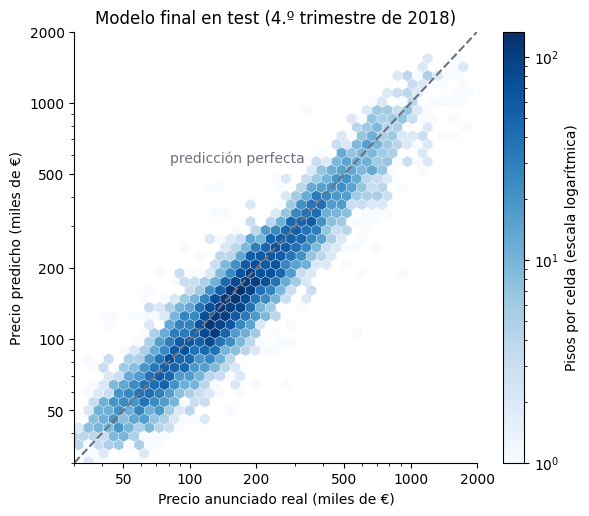

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.6))
hb = ax.hexbin(y_test[nuevos] / 1000, pred_final[nuevos] / 1000, gridsize=45, xscale='log', yscale='log',
               bins='log', cmap='Blues', mincnt=1, linewidths=0.2, edgecolors='white')
limites = [30, 2000]
ax.plot(limites, limites, color='#6b7280', linewidth=1.5, linestyle='--')
ax.text(330, 560, 'predicción perfecta', ha='right', color='#6b7280', fontsize=10)
ax.set(xlim=limites, ylim=limites, xlabel='Precio anunciado real (miles de €)', ylabel='Precio predicho (miles de €)',
       title='Modelo final en test (4.º trimestre de 2018)')
ax.set_xticks([50, 100, 200, 500, 1000, 2000], ['50', '100', '200', '500', '1000', '2000'])
ax.set_yticks([50, 100, 200, 500, 1000, 2000], ['50', '100', '200', '500', '1000', '2000'])
ax.spines[['top', 'right']].set_visible(False)
fig.colorbar(hb, ax=ax, label='Pisos por celda (escala logarítmica)')
plt.show()

## 7. Pruebas de sensatez

Un buen error medio no garantiza que el modelo se comporte con lógica. Se comprueban tres cosas:

1. **Sin fuga:** multiplicar por 3 los precios del test no cambia sus predicciones.
2. **Superficie:** a más metros, el precio estimado de un mismo piso debe subir.
3. **Ubicación:** el mismo piso debe valer más en el centro que lejos de él. No se exige que el precio baje siempre con la distancia, porque los datos no lo respaldan: a más de 4 km casi todos los anuncios están al este de la ciudad, hacia la costa, y su mediana de €/m² es similar a la de unos 2 km.

In [11]:
# 1. Sin fuga: el modelo se ajusta solo con desarrollo y no depende de los precios del test.
alterado = data.copy()
alterado.loc[alterado['PERIOD'] == 201812, 'PRICE'] *= 3
d2 = alterado[alterado['PERIOD'] < 201812]
t2 = alterado[alterado['PERIOD'] == 201812]
pred_alterado = clone(candidatos[elegido]).fit(d2[VARIABLES], d2['PRICE']).predict(t2[VARIABLES])
assert np.array_equal(pred_alterado, pred_final), 'Las predicciones no deben depender de los precios del test'
print('1. Sin fuga: las predicciones no cambian.')

# 2. Superficie: pisos reales del test con su superficie aumentada.
mas_grandes = X_test.copy()
mas_grandes['CONSTRUCTEDAREA'] *= 1.3
sube = final.predict(mas_grandes) / pred_final - 1
print(f'2. Con un 30% más de superficie, el precio estimado sube de mediana un {np.median(sube):.1%}; '
      f'sube en el {(sube > 0).mean():.1%} de los pisos.')
assert np.median(sube) > 0.05

# 3. Ubicación: un piso típico, situado en anuncios reales cerca y lejos del centro.
GEO = ['DISTANCE_TO_CITY_CENTER', 'DISTANCE_TO_METRO', 'DISTANCE_TO_BLASCO', 'LONGITUDE', 'LATITUDE']
tipico = X_dev.median().to_frame().T
tipico['CONSTRUCTEDAREA'], tipico['ROOMNUMBER'], tipico['BATHNUMBER'] = 90, 3, 2
centro = X_dev[X_dev['DISTANCE_TO_CITY_CENTER'] <= 0.5][GEO]
periferia = X_dev[X_dev['DISTANCE_TO_CITY_CENTER'] >= 4][GEO]


intermedia = X_dev[X_dev['DISTANCE_TO_CITY_CENTER'].between(1.8, 2.4)][GEO]


def estimar_en(ubicaciones, area=90, modelo=None):
    # Usa ubicaciones reales: las medianas de cada coordenada por separado no corresponden a ningún lugar.
    filas = pd.concat([tipico.drop(columns=GEO)] * len(ubicaciones), ignore_index=True)
    filas[GEO] = ubicaciones.to_numpy()
    filas['CONSTRUCTEDAREA'] = area
    return np.median((modelo or final).predict(filas[VARIABLES]))


en_centro, en_intermedia, en_periferia = estimar_en(centro), estimar_en(intermedia), estimar_en(periferia)
print('3. Piso típico de 90 m², según la distancia al centro:')
for etiqueta, estimado, zona in [('Hasta 0,5 km', en_centro, centro), ('De 1,8 a 2,4 km', en_intermedia, intermedia),
                                 ('Más de 4 km', en_periferia, periferia)]:
    real_m2 = desarrollo.loc[zona.index, 'UNITPRICE'].median()
    print(f'   {etiqueta}: {estimado:,.0f} € ({estimado / 90:,.0f} €/m²); mediana real de los anuncios: {real_m2:,.0f} €/m²')
print(f"   Más de 4 km y al este de la longitud -0,335: {(periferia['LONGITUDE'] > -0.335).mean():.1%} de los anuncios")
assert en_centro > max(en_intermedia, en_periferia)

print('\nEjemplo de estimación según la superficie, a distancia intermedia del centro:')
estimaciones = {area: estimar_en(intermedia, area) for area in [60, 90, 120, 150]}
for area, valor in estimaciones.items():
    print(f'  {area} m²: {valor:,.0f} €')
assert list(estimaciones.values()) == sorted(estimaciones.values())

1. Sin fuga: las predicciones no cambian.
2. Con un 30% más de superficie, el precio estimado sube de mediana un 20.6%; sube en el 97.2% de los pisos.


3. Piso típico de 90 m², según la distancia al centro:
   Hasta 0,5 km: 219,562 € (2,440 €/m²); mediana real de los anuncios: 2,515 €/m²
   De 1,8 a 2,4 km: 117,734 € (1,308 €/m²); mediana real de los anuncios: 1,302 €/m²
   Más de 4 km: 143,303 € (1,592 €/m²); mediana real de los anuncios: 1,275 €/m²
   Más de 4 km y al este de la longitud -0,335: 96.0% de los anuncios

Ejemplo de estimación según la superficie, a distancia intermedia del centro:


  60 m²: 86,614 €
  90 m²: 117,734 €
  120 m²: 134,934 €
  150 m²: 162,264 €


## 8. ¿Qué variables usa el modelo?

Importancia por permutación sobre una muestra del test: cuánto empeora el MAE si se desordena cada variable. Las medidas de ubicación están relacionadas entre sí y se reparten la importancia, de modo que la suma de la ubicación pesa más de lo que indica cada barra.

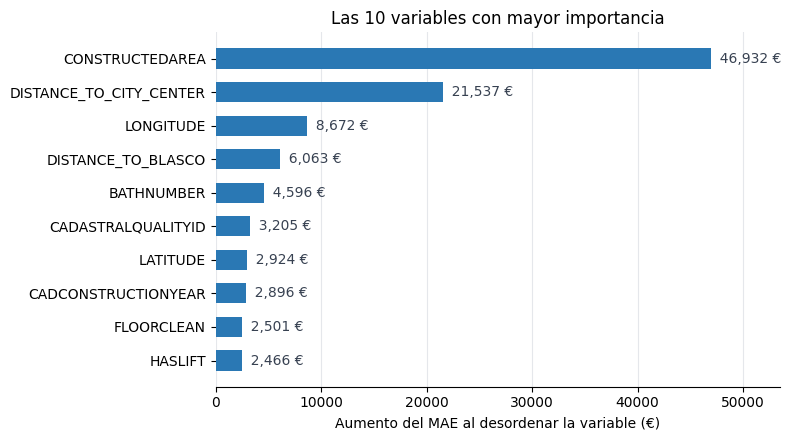

In [12]:
muestra = test[nuevos].sample(3000, random_state=SEED)
imp = permutation_importance(final, muestra[VARIABLES], muestra['PRICE'], scoring='neg_mean_absolute_error',
                             n_repeats=5, random_state=SEED, n_jobs=-1)
top = pd.Series(imp.importances_mean, index=VARIABLES).sort_values(ascending=False).head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=COLOR, height=0.6)
for nombre, valor in top.items():
    ax.text(valor, nombre, f'  {valor:,.0f} €', va='center', fontsize=10, color='#374151')
ax.set(xlabel='Aumento del MAE al desordenar la variable (€)', title='Las 10 variables con mayor importancia')
ax.margins(x=0.14)
ax.grid(axis='x', color='#e5e7eb', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Llevar la estimación a 2026

Los pisos anunciados son de 2018, pero existe una serie reciente: el [valor tasado medio de la vivienda libre](https://apps.fomento.gob.es/BoletinOnline2/sedal/35103500.XLS) en el municipio de València, que publica el Ministerio de Vivienda y Agenda Urbana. Se puede usar para reescalar el modelo: **precio estimado en 2018 × (valor tasado actual / valor tasado de 2018)**.

Es una aproximación con supuestos fuertes:

- Se aplica el mismo factor a toda la ciudad, aunque unos barrios hayan subido más que otros.
- Mide tasaciones, no precios anunciados. Solo se usa cómo evoluciona, no su nivel.
- El índice varía de un trimestre a otro aunque se base en muchas tasaciones (de 1.343 a 2.999 en esta serie): subió un 12,8 % solo entre el tercer y el cuarto trimestre de 2018. El resultado depende de qué trimestres se comparen, y por eso se da un rango.

Primero se comprueba el método donde sí se puede medir: ¿corrige el índice el sesgo del cuarto trimestre de 2018?

In [13]:
# (año, trimestre): (valor tasado total en €/m², número total de tasaciones). Municipio de València.
# Fuente: Ministerio de Vivienda y Agenda Urbana, tabla 35103500, consultada el 7 de noviembre de 2026.
TASADO = {
    (2018, 1): (1235.6, 2192), (2018, 2): (1244.5, 2491), (2018, 3): (1211.6, 1911), (2018, 4): (1367.1, 2211),
    (2019, 1): (1410.4, 2012), (2019, 2): (1461.0, 1954), (2019, 3): (1397.6, 1860), (2019, 4): (1486.1, 2284),
    (2020, 1): (1506.9, 2202), (2020, 2): (1421.7, 1343), (2020, 3): (1508.1, 2312), (2020, 4): (1502.2, 2382),
    (2021, 1): (1514.7, 2452), (2021, 2): (1592.0, 2733), (2021, 3): (1580.1, 1957), (2021, 4): (1679.2, 2576),
    (2022, 1): (1696.9, 2766), (2022, 2): (1701.3, 2835), (2022, 3): (1685.3, 2251), (2022, 4): (1753.9, 2551),
    (2023, 1): (1833.9, 2273), (2023, 2): (1880.1, 2468), (2023, 3): (1880.8, 1895), (2023, 4): (1976.4, 2611),
    (2024, 1): (2068.4, 2391), (2024, 2): (2077.7, 2846), (2024, 3): (2194.7, 2223), (2024, 4): (2400.9, 2348),
    (2025, 1): (2485.5, 2411), (2025, 2): (2541.7, 2844), (2025, 3): (2725.9, 2362), (2025, 4): (2791.0, 2999),
    (2026, 1): (2907.9, 2519), (2026, 2): (2972.8, 2735),
}
valor = {clave: v[0] for clave, v in TASADO.items()}
trimestre = {201803: (2018, 1), 201806: (2018, 2), 201809: (2018, 3), 201812: (2018, 4)}


def tasado_medio(tabla):
    # Media del valor tasado de cada trimestre, ponderada por el número de pisos de la tabla.
    return tabla['PERIOD'].map(trimestre).map(valor).mean()


# Prueba: el modelo se entrenó con Q1-Q3 y se evalúa en Q4.
factor_q4 = valor[(2018, 4)] / tasado_medio(desarrollo)
pred_ajustada = pred_final * factor_q4
print(f'Factor del índice de Q1-Q3 a Q4 de 2018: {factor_q4:.3f}')
print(f"Subida de la mediana de €/m² anunciado, de Q1-Q3 a Q4: {test['UNITPRICE'].median() / desarrollo['UNITPRICE'].median():.3f}")
pd.DataFrame([
    resumen('Modelo sin ajustar', y_test[nuevos], pred_final[nuevos]),
    resumen('Modelo ajustado con el índice', y_test[nuevos], pred_ajustada[nuevos]),
]).set_index('modelo')

Factor del índice de Q1-Q3 a Q4 de 2018: 1.111
Subida de la mediana de €/m² anunciado, de Q1-Q3 a Q4: 1.094


,filas,MAE,MedAE,MAPE,R2,Sesgo mediano
modelo,,,,,,
Modelo sin ajustar,8998,"35,934","19,936",0.166,0.852,-0.056
Modelo ajustado con el índice,8998,"37,319","20,915",0.182,0.855,0.048


In [14]:
modelo_2018 = clone(candidatos[elegido]).fit(data[VARIABLES], data['PRICE'])
base_2018 = tasado_medio(data)
ultimos = (valor[(2026, 1)] + valor[(2026, 2)]) / 2

factor_bajo = ultimos / valor[(2018, 4)]
factor_alto = valor[(2026, 2)] / base_2018
print(f'Factor de 2018 a 2026: de {factor_bajo:.2f} a {factor_alto:.2f}')

# Contraste externo: precio anunciado de pisos en València publicado por idealista para junio de 2026.
IDEALISTA_JUNIO_2026 = 3364
mediana_2018 = data['UNITPRICE'].median()
print(f'Mediana anunciada en 2018: {mediana_2018:,.0f} €/m². Reescalada a 2026: '
      f'de {mediana_2018 * factor_bajo:,.0f} a {mediana_2018 * factor_alto:,.0f} €/m². '
      f'Publicado por idealista: {IDEALISTA_JUNIO_2026:,} €/m².')

filas = []
for etiqueta, zona in [('Hasta 0,5 km del centro', centro), ('De 1,8 a 2,4 km', intermedia), ('Más de 4 km', periferia)]:
    for area in [70, 90, 120]:
        en_2018 = estimar_en(zona, area, modelo_2018)
        filas.append({'zona': etiqueta, 'm²': area, 'Estimado 2018 (€)': en_2018,
                      '2026, bajo (€)': en_2018 * factor_bajo, '2026, alto (€)': en_2018 * factor_alto})
pd.DataFrame(filas).set_index(['zona', 'm²']).round(-3)

Factor de 2018 a 2026: de 2.15 a 2.32
Mediana anunciada en 2018: 1,516 €/m². Reescalada a 2026: de 3,260 a 3,516 €/m². Publicado por idealista: 3,364 €/m².


Estimado 2018 (€)  2026, bajo (€)  2026, alto (€)
zona                    m²                                                    
Hasta 0,5 km del centro 70             213,000         459,000         495,000
                        90             244,000         524,000         565,000
                        120            269,000         579,000         624,000
De 1,8 a 2,4 km         70              98,000         211,000         228,000
                        90             128,000         275,000         297,000
                        120            135,000         290,000         313,000
Más de 4 km             70             137,000         295,000         318,000
                        90             151,000         324,000         350,000
                        120            159,000         342,000         369,000

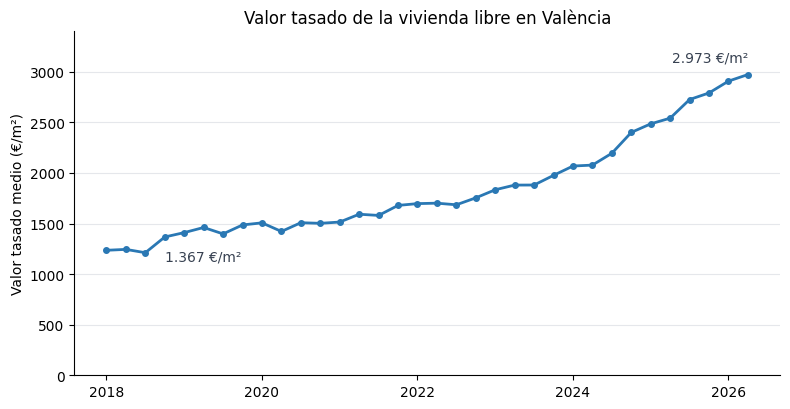

In [15]:
claves = list(valor)
tiempo = [a + (t - 1) / 4 for a, t in claves]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tiempo, [valor[c] for c in claves], color=COLOR, linewidth=2, marker='o', markersize=4)
for clave, alinear, dy in [((2018, 4), 'left', -230), ((2026, 2), 'right', 130)]:
    x = clave[0] + (clave[1] - 1) / 4
    ax.text(x, valor[clave] + dy, f'{valor[clave]:,.0f} €/m²'.replace(',', '.'), ha=alinear, fontsize=10, color='#374151')
ax.set(ylim=(0, 3400), ylabel='Valor tasado medio (€/m²)', title='Valor tasado de la vivienda libre en València')
ax.grid(axis='y', color='#e5e7eb', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 10. Conclusiones

Resultados en el cuarto trimestre de 2018, sin las posibles re-publicaciones (8.998 pisos):

| Modelo | MAE | Error mediano | MAPE | R² |
| --- | --- | --- | --- | --- |
| €/m² de toda la ciudad | 78.365 € | 43.071 € | 37,1 % | 0,375 |
| €/m² por zona | 50.217 € | 29.243 € | 24,4 % | 0,748 |
| Gradient boosting + log, ajustado | **35.934 €** | **19.936 €** | **16,6 %** | **0,852** |

1. **El modelo aporta valor real.** Reduce el MAE en 14.267 € frente al precio por m² de la zona (IC 95%: 13.285 a 15.237 €).
2. **Sirve para orientarse, no para tasar.** Se equivoca en un 16,6 % de media. El error relativo es menor en los tramos medios (15,8-15,9 %) y mayor en los extremos: 18,0 % hasta 100.000 € y 18,9 % por encima de 400.000 €.
3. **La revisión de los datos fue decisiva.** Con `UNITPRICE`, el error habría bajado a un 1,46 % en validación, un resultado falso. Sin tratar `-2147483648`, los años de construcción y las plantas también habrían sido incorrectos.
4. **Las posibles re-publicaciones mejoran un poco la métrica.** Incluirlas baja el MAE de 35.934 € a 34.347 €, por eso la cifra principal las excluye.
5. **El modelo tiende a quedarse corto.** La predicción mediana queda un 5,6 % por debajo del precio anunciado. La mediana de €/m² pasó de 1.508 € en el tercer trimestre a 1.600 € en el cuarto, y un modelo entrenado antes no puede conocer esa subida. Los datos no permiten separar si el precio subió o si cambió el tipo de pisos anunciados.
6. **La estimación para 2026 es una orientación a nivel de ciudad, no una predicción validada.** El factor va de 2,15 a 2,32. Aplicado a la mediana de 2018 da de 3.260 a 3.516 €/m², un rango que incluye los 3.364 €/m² que idealista publica para junio de 2026. Ese contraste es solo para la ciudad en conjunto: no comprueba zonas ni pisos concretos.
7. **El índice no mejora la predicción a corto plazo.** En el cuarto trimestre de 2018 lleva el sesgo de -5,6 % a +4,8 % y empeora el MAE de 35.934 € a 37.319 €. El índice subió un 11,1 % y la mediana anunciada un 9,4 %, por lo que corrige de más. Por eso la evaluación del modelo sigue siendo la de 2018, sin reescalar.

**Límites:**

- Predice precios **anunciados**, no precios de venta. La diferencia entre ambos no se puede medir con estos datos.
- Los datos son de **2018**. Las estimaciones para 2026 aplican el mismo factor a toda la ciudad y no se pueden validar con datos de pisos actuales.
- Precios y coordenadas llevan ruido añadido, lo que limita la precisión alcanzable.
- Solo cubre la ciudad de València y pisos anunciados en idealista.
- La importancia de las variables describe el modelo, no las causas del precio.
- A más de 4 km del centro, el piso típico se estima en 1.592 €/m² y la mediana real de los anuncios es de 1.275 €/m². Puede deberse a que allí los pisos son distintos, pero no se ha comprobado.
- Las cifras no son comparables directamente con las de Ames: otra ciudad, otra época y otro tipo de precio.
- Los números y la lectura de los datos pueden variar con otras versiones de las librerías, ya que `requirements.txt` no fija versiones.
